# Bài 6 (trang PDF 45, Groceries) – Câu 6

**Sinh viên:** Trần Chí Nguyên  
**MSSV:** 6451071052

Notebook chạy độc lập trên Google Colab. Dữ liệu công khai được tải tự động khi chạy cell đầu tiên.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import csv, requests, time, numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

print("Trần Chí Nguyên - 6451071052")
FILE_ID = "1UIeIAeGPrmXaSsFOtfhw9h5gK4RPkseI"
def load_groceries():
    path = Path("/content/groceries.csv")
    if not path.exists():
        response = requests.get("https://drive.google.com/uc", params={"export": "download", "id": FILE_ID}, timeout=90)
        response.raise_for_status()
        path.write_bytes(response.content)
    with path.open(encoding="utf-8-sig", newline="") as handle:
        return [[item.strip() for item in row if item.strip()] for row in csv.reader(handle)]
transactions = load_groceries()
print(f"Số giao dịch: {len(transactions):,}; số mặt hàng duy nhất: {len(set(x for t in transactions for x in t)):,}")

Trần Chí Nguyên - 6451071052
Số giao dịch: 9,835; số mặt hàng duy nhất: 169


## Thực hiện yêu cầu

Cell dưới đây chứa lời giải cho câu này.

In [2]:
import itertools, math

# Apriori theo từng mức (level-wise): sinh ứng viên -> tỉa theo tính chất Apriori -> đếm support.
# Đếm support bằng bitset (np.packbits) để nhanh và không tốn RAM như mlxtend.apriori khi min_sup rất nhỏ.
_POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint16)

def _count(packed, idx_rows, chunk=4000):
    out = np.empty(len(idx_rows), dtype=np.int64)
    for s in range(0, len(idx_rows), chunk):
        sub = idx_rows[s:s+chunk]
        v = packed[sub[:, 0]]
        for c in range(1, sub.shape[1]):
            v = v & packed[sub[:, c]]
        out[s:s+chunk] = _POP[v].sum(axis=1)
    return out

def apriori_fast(onehot, min_support, max_len=3):
    X = onehot.to_numpy(dtype=bool); n, m = X.shape; cols = onehot.columns
    packed = np.packbits(X.T, axis=1)
    min_count = math.ceil(min_support * n - 1e-9)
    c1 = X.sum(axis=0)
    L = [i for i in range(m) if c1[i] >= min_count]
    rows = [(frozenset([cols[i]]), c1[i] / n) for i in L]
    prev = [(i,) for i in L]
    for k in range(2, max_len + 1):
        if k == 2:
            cand = list(itertools.combinations(L, 2))
        else:
            prev_set = set(prev); cand = []
            for a, b in itertools.combinations(prev, 2):
                if a[:-1] == b[:-1]:
                    c = a + (b[-1],)
                    if all(t in prev_set for t in itertools.combinations(c, k - 1)):
                        cand.append(c)
        if not cand: break
        arr = np.array(cand, dtype=np.int64)
        cnt = _count(packed, arr)
        keep = cnt >= min_count
        prev = [tuple(r) for r in arr[keep]]
        rows += [(frozenset(cols[j] for j in r), c / n) for r, c in zip(prev, cnt[keep])]
        if not prev: break
    return pd.DataFrame({"support": [r[1] for r in rows], "itemsets": [r[0] for r in rows]})

,min_support,patterns_apriori,seconds_apriori,patterns_fpgrowth,seconds_fpgrowth
0,0.0001,149229,10.973788,149229,4.222107
1,0.0002,70858,6.394046,70858,2.241650
2,0.0003,44260,4.057849,44260,2.072395
3,0.0004,31576,3.310724,31576,1.477439
4,0.0005,24172,2.568169,24172,1.270659
5,0.0006,19251,2.241384,19251,1.076039
6,0.0007,15844,1.908174,15844,0.940779
7,0.0008,13340,1.769826,13340,0.971167
8,0.0009,11438,1.499338,11438,0.742282
9,0.0010,9969,1.185272,9969,0.700079


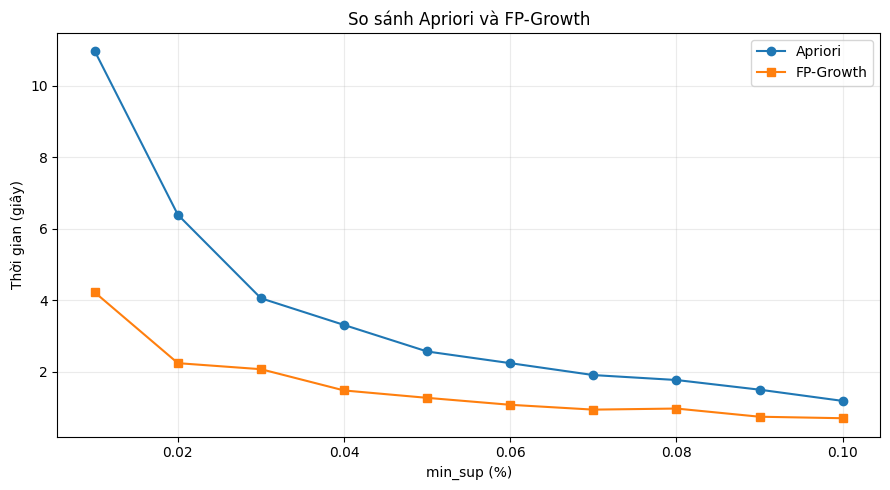

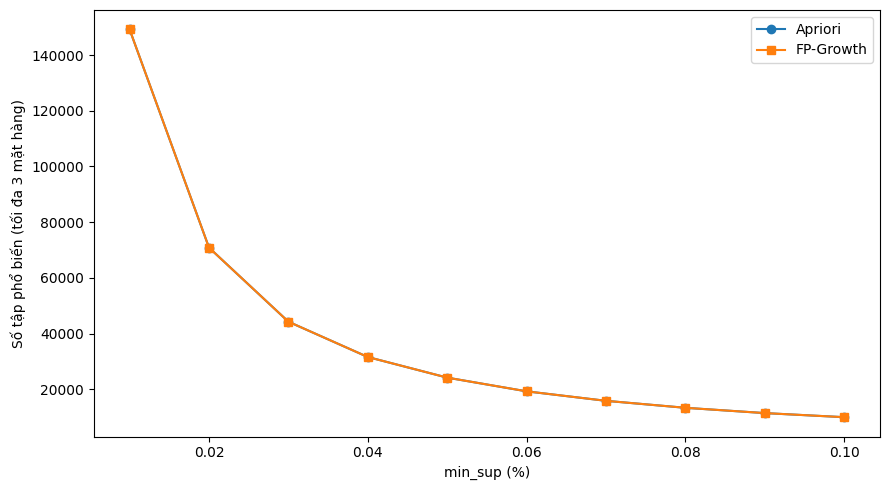

Nhận xét: hai thuật toán phải tìm cùng tập phổ biến khi cùng ngưỡng và cùng giới hạn độ dài. FP-Growth thường nhanh hơn vì không sinh tập ứng viên; thời gian thực tế phụ thuộc máy và phiên bản thư viện.


In [3]:
%pip -q install mlxtend
import warnings
warnings.filterwarnings("ignore")
from mlxtend.frequent_patterns import fpgrowth
from mlxtend.preprocessing import TransactionEncoder

encoder = TransactionEncoder()
encoded = encoder.fit(transactions).transform(transactions)
onehot = pd.DataFrame(encoded, columns=encoder.columns_)

MIN_SUPPORTS = np.round(np.arange(0.0001, 0.00101, 0.0001), 4).tolist()
MAX_ITEMSET_LENGTH = 3
apriori_results, fpgrowth_results = [], []
for min_sup in MIN_SUPPORTS:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        start = time.perf_counter()
        frequent = apriori_fast(onehot, min_sup, max_len=MAX_ITEMSET_LENGTH)
        apriori_results.append({"min_support": min_sup, "patterns": len(frequent), "seconds": time.perf_counter() - start})
        start = time.perf_counter()
        frequent = fpgrowth(onehot, min_support=min_sup, use_colnames=True, max_len=MAX_ITEMSET_LENGTH)
        fpgrowth_results.append({"min_support": min_sup, "patterns": len(frequent), "seconds": time.perf_counter() - start})
apriori_results = pd.DataFrame(apriori_results)
fpgrowth_results = pd.DataFrame(fpgrowth_results)
comparison = apriori_results.merge(fpgrowth_results, on="min_support", suffixes=("_apriori", "_fpgrowth"))
display(comparison)

plt.figure(figsize=(9, 5))
plt.plot(comparison["min_support"] * 100, comparison["seconds_apriori"], marker="o", label="Apriori")
plt.plot(comparison["min_support"] * 100, comparison["seconds_fpgrowth"], marker="s", label="FP-Growth")
plt.xlabel("min_sup (%)"); plt.ylabel("Thời gian (giây)"); plt.title("So sánh Apriori và FP-Growth")
plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 5))
plt.plot(comparison["min_support"] * 100, comparison["patterns_apriori"], marker="o", label="Apriori")
plt.plot(comparison["min_support"] * 100, comparison["patterns_fpgrowth"], marker="s", label="FP-Growth")
plt.xlabel("min_sup (%)"); plt.ylabel("Số tập phổ biến (tối đa 3 mặt hàng)")
plt.legend(); plt.tight_layout(); plt.show()

print("Nhận xét: hai thuật toán phải tìm cùng tập phổ biến khi cùng ngưỡng và cùng giới hạn độ dài. FP-Growth thường nhanh hơn vì không sinh tập ứng viên; thời gian thực tế phụ thuộc máy và phiên bản thư viện.")